In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, classification_report

In [3]:
df = pd.read_csv("/content/synthetic_diabetes_5000.csv")

print("First 5 Records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

First 5 Records:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            4       85             74             24      154  18.4   
1            4      117             64             15       59  15.0   
2            5      113             91             20       64  45.9   
3            1      110             84             23       31  29.5   
4            7      175             57             34       59  37.8   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.235   22        0  
1                     0.306   32        0  
2                     0.488   35        0  
3                     0.600   27        0  
4                     0.264   38        0  

Dataset Shape:
(5000, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies      

In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Replace impossible zero values with NaN
cols = ['Glucose', 'BloodPressure', 'SkinThickness',
        'Insulin', 'BMI']

df[cols] = df[cols].replace(0, np.nan)

# Fill missing values using median
for col in cols:
    df[col] = df[col].fillna(df[col].median())

# Check duplicates and missing values again
print("\nMissing Values After Preprocessing:")
print(df.isnull().sum())

print("\nDataset Shape After Preprocessing:")
print(df.shape)

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Missing Values After Preprocessing:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Dataset Shape After Preprocessing:
(5000, 9)


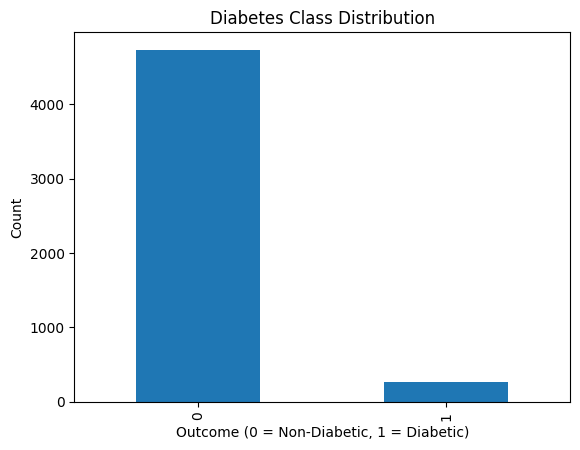

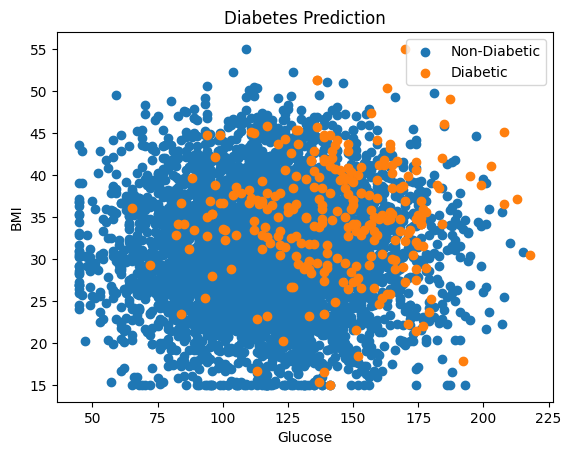

In [5]:
# Class distribution
df['Outcome'].value_counts().plot(
    kind='bar',
    title='Diabetes Class Distribution'
)

plt.xlabel('Outcome (0 = Non-Diabetic, 1 = Diabetic)')
plt.ylabel('Count')
plt.show()

# Scatter plot
plt.scatter(df[df['Outcome'] == 0]['Glucose'],
            df[df['Outcome'] == 0]['BMI'],
            label='Non-Diabetic')

plt.scatter(df[df['Outcome'] == 1]['Glucose'],
            df[df['Outcome'] == 1]['BMI'],
            label='Diabetic')

plt.xlabel('Glucose')
plt.ylabel('BMI')
plt.title('Diabetes Prediction')
plt.legend()
plt.show()


In [6]:
X = df.drop('Outcome', axis=1).values

y = df['Outcome'].values

print("Input Features:")
print(X[:5])

print("\nTarget Output:")
print(y[:5])

Input Features:
[[  4.     85.     74.     24.    154.     18.4     0.235  22.   ]
 [  4.    117.     64.     15.     59.     15.      0.306  32.   ]
 [  5.    113.     91.     20.     64.     45.9     0.488  35.   ]
 [  1.    110.     84.     23.     31.     29.5     0.6    27.   ]
 [  7.    175.     57.     34.     59.     37.8     0.264  38.   ]]

Target Output:
[0 0 0 0 0]


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4000, 8)
Testing Data: (1000, 8)


In [8]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Scaled Training Data:")
print(X_train[:5])

Scaled Training Data:
[[ 1.30127015 -1.91117258  0.48627724  0.56689662 -1.0898696   0.80491854
   1.26681337 -0.47737881]
 [ 0.70701503  0.78712435 -0.00540854 -0.23668285 -0.56165051 -0.87153985
  -0.84254298 -0.77032413]
 [ 1.30127015 -0.52743056  1.79743932 -1.4994506   0.69960732 -1.24408616
  -0.34396784 -0.37973037]
 [-0.48149521 -0.63121122  0.07653909 -0.92546526 -0.43229073 -1.97485007
  -1.07052392  0.98734779]
 [ 0.11275991 -0.90795962 -0.08735617  0.10770835  0.31152799  1.07716392
   1.84422304 -1.55151165]]


In [9]:
X_train = np.c_[np.ones(X_train.shape[0]), X_train]

X_test = np.c_[np.ones(X_test.shape[0]), X_test]

print("Input Vector X:")
print(X_train[:5])

Input Vector X:
[[ 1.          1.30127015 -1.91117258  0.48627724  0.56689662 -1.0898696
   0.80491854  1.26681337 -0.47737881]
 [ 1.          0.70701503  0.78712435 -0.00540854 -0.23668285 -0.56165051
  -0.87153985 -0.84254298 -0.77032413]
 [ 1.          1.30127015 -0.52743056  1.79743932 -1.4994506   0.69960732
  -1.24408616 -0.34396784 -0.37973037]
 [ 1.         -0.48149521 -0.63121122  0.07653909 -0.92546526 -0.43229073
  -1.97485007 -1.07052392  0.98734779]
 [ 1.          0.11275991 -0.90795962 -0.08735617  0.10770835  0.31152799
   1.07716392  1.84422304 -1.55151165]]


In [10]:
Y_train = np.where(y_train == 1, 1, -1)

Y_test = np.where(y_test == 1, 1, -1)

print("Desired Output Y:")
print(Y_train[:10])

Desired Output Y:
[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1]


In [11]:
W = np.zeros(X_train.shape[1])

learning_rate = 0.01

epochs = 100

print("Initial Weight Vector:")
print(W)

print("Learning Rate:", learning_rate)

Initial Weight Vector:
[0. 0. 0. 0. 0. 0. 0. 0. 0.]
Learning Rate: 0.01


In [12]:
errors = []

for epoch in range(epochs):

    total_error = 0

    for i in range(len(X_train)):

        v = np.dot(W, X_train[i])

        T = 1 if v >= 0 else -1

        if Y_train[i] != T:

            W = W + learning_rate * (Y_train[i] - T) * X_train[i]

            total_error += 1

    errors.append(total_error)

print("Final Weight Vector:")
print(W)

Final Weight Vector:
[-0.16        0.04138393  0.0435685  -0.06797064  0.04475708 -0.01125214
  0.0772598  -0.00671176  0.02950936]


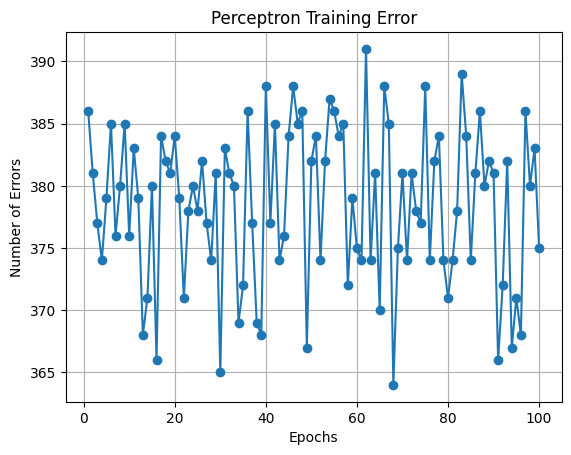

In [13]:
plt.plot(range(1, epochs + 1), errors, marker='o')

plt.xlabel('Epochs')
plt.ylabel('Number of Errors')

plt.title('Perceptron Training Error')

plt.grid()
plt.show()

In [14]:
y_pred = []

for i in range(len(X_test)):

    v = np.dot(W, X_test[i])

    T = 1 if v >= 0 else -1

    y_pred.append(T)

y_pred = np.array(y_pred)

accuracy = accuracy_score(Y_test, y_pred)

print("Actual Output:")
print(Y_test[:20])

print("\nPredicted Output:")
print(y_pred[:20])

print("\nAccuracy:", accuracy * 100, "%")

print("\nConfusion Matrix:")
print(confusion_matrix(Y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    Y_test,
    y_pred,
    labels=[-1, 1],
    target_names=['Non-Diabetic', 'Diabetic'],
    zero_division=0
))

Actual Output:
[-1 -1 -1  1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]

Predicted Output:
[-1  1 -1 -1 -1 -1 -1 -1 -1  1 -1 -1 -1 -1  1 -1 -1 -1 -1 -1]

Accuracy: 86.5 %

Confusion Matrix:
[[849  97]
 [ 38  16]]

Classification Report:
              precision    recall  f1-score   support

Non-Diabetic       0.96      0.90      0.93       946
    Diabetic       0.14      0.30      0.19        54

    accuracy                           0.86      1000
   macro avg       0.55      0.60      0.56      1000
weighted avg       0.91      0.86      0.89      1000



In [15]:
# New patient data
# Order: Pregnancies, Glucose, BloodPressure,
# SkinThickness, Insulin, BMI,
# DiabetesPedigreeFunction, Age

new_data = np.array([[2, 150, 80, 25, 120, 32.5, 0.5, 35]])

# Apply the same feature scaling
new_data_scaled = scaler.transform(new_data)

# Add bias
new_data_scaled = np.c_[np.ones(new_data_scaled.shape[0]), new_data_scaled]

# Prediction
v = np.dot(W, new_data_scaled[0])

prediction = 1 if v >= 0 else -1

# Display result
if prediction == 1:
    print("Prediction: Diabetic")
else:
    print("Prediction: Non-Diabetic")

Prediction: Non-Diabetic
